# Two-Stage DiD

Gardner's (2022) two-stage estimator reaches the same destination as the imputation
estimator by a route that looks like ordinary regression: remove unit and period effects
estimated from untreated observations, then regress what is left on treatment. This
tutorial asks **what that buys you: where the two estimators agree exactly, where they
differ, and when to report which.**

**What you'll learn**

- How the two stages work and what they assume
- That the overall and post-treatment estimates are identical to Imputation DiD's, and why
- How the standard errors differ: a GMM sandwich against a conservative estimator
- How to get the event study, cohort effects and observation-level effects from one fit

**Prerequisites:** [Staggered DiD](02_staggered_did.ipynb) and
[Imputation DiD](11_imputation_did.ipynb).

In [1]:
import numpy as np
import pandas as pd

from diff_diff import (
    CallawaySantAnna,
    ImputationDiD,
    TwoStageDiD,
    generate_staggered_data,
    plot_event_study,
)

## What it estimates and assumes

1. **First stage.** Fit unit and period fixed effects on the **untreated observations
   only**: never-treated units, and eventually-treated units before treatment.
2. **Residualise.** Subtract those fitted effects from *every* outcome. For a treated
   observation, the residual is the outcome minus its estimated untreated counterpart.
3. **Second stage.** Regress the residualised outcomes on treatment indicators: one
   indicator for the overall effect, or one per event time or cohort.

Fitting the fixed effects on untreated data is what avoids the problem with an ordinary
two-way fixed effects regression, where already-treated observations help estimate the
period effects and contaminate the comparison.

**Target parameter.** The average treatment effect on the treated (ATT): the average,
over all treated unit-periods, of observed minus untreated outcome.

**Identifying assumptions.** The same as for [Imputation DiD](11_imputation_did.ipynb):

- **Parallel trends:** without treatment, every unit's expected outcome is a unit effect
  plus a period effect, in all periods.
- **No anticipation:** outcomes do not respond before treatment starts.
- Treatment is **absorbing**.

Treatment effects may differ across units, cohorts and time.

**What would violate it.** A cohort already on a different path before treatment, or a
response before the recorded treatment date. Either one enters the first stage as if it
were untreated data.

## Simulated data

The same design as in the Imputation DiD tutorial: 300 units over 10 periods, cohorts
starting treatment in periods 3, 5 and 7, 90 never-treated units, and a true effect of
2.0 in every treated period.

In [2]:
TRUE_ATT = 2.0

data = generate_staggered_data(
    n_units=300,
    n_periods=10,
    treatment_effect=TRUE_ATT,
    dynamic_effects=False,  # constant effect: the same in every period after treatment
    seed=42,
)
fit_args = dict(outcome="outcome", unit="unit", time="period", first_treat="first_treat")

print(f"{data['unit'].nunique()} units, {data['period'].nunique()} periods")
print(f"True ATT: {TRUE_ATT}")

300 units, 10 periods
True ATT: 2.0


## Fitting the estimator

Standard errors are clustered by unit by default. `pretrends=True` adds pre-treatment
coefficients to the event study further down; it does not change the overall estimate.

In [3]:
results = TwoStageDiD(pretrends=True).fit(data, **fit_args)

print(results.summary())

                    Two-Stage DiD Estimator Results (Gardner 2022)                   

Total observations:                  3000
Treated observations:                1020
Untreated observations:              1980
Treated units:                        210
Control units:                        300
Treatment cohorts:                      3
Time periods:                          10

Variance estimator:            CR1 cluster-robust at unit, G=300

-------------------------------------------------------------------------------------
                   Overall Average Treatment Effect on the Treated                   
-------------------------------------------------------------------------------------
Parameter           Estimate    Std. Err.     t-stat      P>|t|   Sig.
-------------------------------------------------------------------------------------
ATT                   1.9817       0.0370     53.551     0.0000    ***
------------------------------------------------------------------

In [4]:
print(f"Estimate: {results.att:.3f}  (SE {results.se:.3f})")
print(f"95% CI:   [{results.conf_int[0]:.3f}, {results.conf_int[1]:.3f}]")
print(f"True ATT: {TRUE_ATT:.3f}")

Estimate: 1.982  (SE 0.037)
95% CI:   [1.909, 2.054]
True ATT: 2.000


The estimate is 1.98 with a 95% interval of [1.91, 2.05], which contains the true effect
of 2.0.

## Event study

`aggregate("event_study")` gives the effect at each time since treatment. The
pre-treatment coefficients are there because the estimator was built with
`pretrends=True`; without it the event study starts at event time -1. Each
pre-treatment coefficient is the average first-stage residual of the eventually-treated
units at that lead. The row at event time -1 is a zero marker for the plot: the other
coefficients are not measured against it.

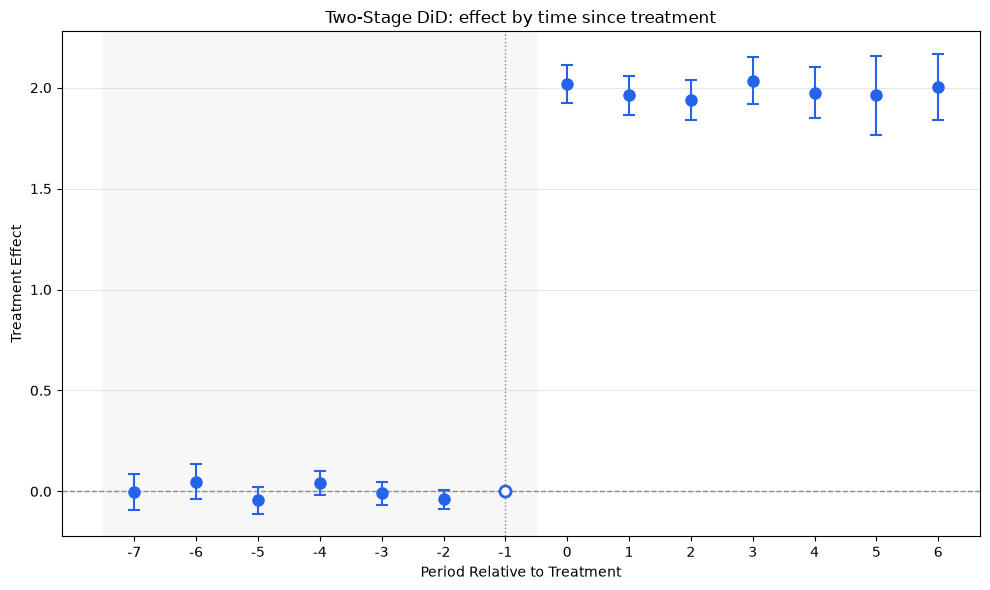

In [5]:
es = results.aggregate("event_study")

ax = plot_event_study(es, title="Two-Stage DiD: effect by time since treatment", show=False)

In [6]:
columns = ["event_time", "att", "se", "conf_int_lower", "conf_int_upper", "is_reference"]
print(es.to_dataframe()[columns].round(3).to_string(index=False))

 event_time    att    se  conf_int_lower  conf_int_upper  is_reference
         -7 -0.005 0.046          -0.094           0.084         False
         -6  0.049 0.044          -0.037           0.135         False
         -5 -0.045 0.033          -0.110           0.020         False
         -4  0.043 0.030          -0.016           0.101         False
         -3 -0.009 0.028          -0.065           0.046         False
         -2 -0.040 0.024          -0.087           0.007         False
         -1  0.000   NaN             NaN             NaN          True
          0  2.018 0.049           1.922           2.113         False
          1  1.962 0.049           1.866           2.057         False
          2  1.937 0.051           1.838           2.036         False
          3  2.033 0.059           1.917           2.150         False
          4  1.975 0.065           1.848           2.102         False
          5  1.961 0.099           1.768           2.155         False
      

After treatment the estimates are close to 2.0 at every horizon, with standard errors
that grow as fewer cohorts are observed that long after treatment.

Before treatment the coefficients are within about 0.05 of zero. Several are between one
and two standard errors away, which is unremarkable among six coefficients. As always,
small pre-treatment coefficients are the absence of visible evidence against parallel
trends, not confirmation of it; see [Pre-Trends Power](07_pretrends_power.ipynb) and
[Honest DiD Sensitivity](05_honest_did.ipynb). Neither takes this estimator's event study. Run them on a
`CallawaySantAnna(base_period="universal")` fit of the same data, and read what they
report as a statement about that fit's comparisons, not this one's.

## Observation-level effects

The residual of each treated observation is its own estimated effect. `treatment_effects`
holds one row per treated unit-period: `tau_hat` is that estimate, `rel_time` the time
since treatment, and `weight` the weight the observation gets in the overall ATT.

In [7]:
effects = results.treatment_effects

print(f"{len(effects)} treated observations")
print(effects.head().round(4).to_string(index=False))
print()
print(f"Weighted average of tau_hat: {(effects['tau_hat'] * effects['weight']).sum():.4f}")
print(f"Overall ATT:                 {results.att:.4f}")
print(f"SD of tau_hat across observations: {effects['tau_hat'].std():.3f}")

1020 treated observations
 unit  period  tau_hat  rel_time  weight
   90       3   1.7813       0.0   0.001
   90       4   2.8828       1.0   0.001
   90       5   0.9251       2.0   0.001
   90       6   2.0912       3.0   0.001
   90       7   1.6769       4.0   0.001

Weighted average of tau_hat: 1.9817
Overall ATT:                 1.9817
SD of tau_hat across observations: 0.563


The weighted average of the observation-level estimates is the overall ATT, by
construction. Individually they are very noisy: each one contains that observation's
own error term, so their standard deviation, 0.56, is close to the noise in the data
(0.5), although the true effect is exactly 2.0 for every one of them. Use them to
build averages over groups you care about, or to look for a handful of units driving
the result. Do not read the spread of `tau_hat` as heterogeneity in the effect.

## Effects by cohort

The same fit gives an effect per cohort.

In [8]:
columns = ["label", "att", "se", "conf_int_lower", "conf_int_upper", "n"]
print(results.aggregate("group").to_dataframe()[columns].round(3).to_string(index=False))

label   att    se  conf_int_lower  conf_int_upper     n
    3 2.005 0.050           1.907           2.103 420.0
    5 1.999 0.049           1.903           2.095 375.0
    7 1.908 0.055           1.800           2.017 225.0


## Comparison with Imputation DiD and Callaway-Sant'Anna

Two-Stage DiD and Imputation DiD estimate the same fixed effects on the same untreated
observations, so their overall and post-treatment estimates are identical. They differ
in the standard error of those estimates:

- **Two-Stage DiD** uses a GMM sandwich (Butts & Gardner 2022) that treats the two stages
  as one system, so the uncertainty from estimating the fixed effects carries into the
  second stage.
- **Imputation DiD** uses the conservative estimator of Borusyak, Jaravel & Spiess (2024,
  Theorem 3).

Callaway-Sant'Anna is a different estimator: it compares each cohort with the
never-treated units from the period before treatment, and by default reports analytical
standard errors from its influence function.

In [9]:
imputation = ImputationDiD(pretrends=True).fit(data, **fit_args)
callaway = CallawaySantAnna().fit(data, **fit_args)

print(f"{'Estimator':<18} {'ATT':>8} {'SE':>8} {'95% CI':>18} {'covers 2.0':>11}")
for name, fit in [("TwoStageDiD", results), ("ImputationDiD", imputation), ("CallawaySantAnna", callaway)]:
    lower, upper = fit.conf_int
    print(
        f"{name:<18} {fit.att:>8.4f} {fit.se:>8.4f} {f'[{lower:.3f}, {upper:.3f}]':>18} "
        f"{str(lower <= TRUE_ATT <= upper):>11}"
    )

print(f"\nTwo-stage minus imputation estimate: {results.att - imputation.att:.1e}")

Estimator               ATT       SE             95% CI  covers 2.0
TwoStageDiD          1.9817   0.0370     [1.909, 2.054]        True
ImputationDiD        1.9817   0.0369     [1.909, 2.054]        True
CallawaySantAnna     1.9754   0.0528     [1.872, 2.079]        True

Two-stage minus imputation estimate: 0.0e+00


In [10]:
two_stage_es = es.to_dataframe().set_index("event_time")
imputation_es = imputation.aggregate("event_study").to_dataframe().set_index("event_time")

comparison = pd.DataFrame(
    {
        "effect": two_stage_es["att"],
        "GMM SE": two_stage_es["se"],
        "Imputation SE": imputation_es["se"],
    }
)
comparison["ratio"] = comparison["GMM SE"] / comparison["Imputation SE"]
print(comparison[~two_stage_es["is_reference"]].round(4).to_string())

            effect  GMM SE  Imputation SE   ratio
event_time                                       
-7         -0.0050  0.0456         0.1050  0.4339
-6          0.0488  0.0440         0.0996  0.4416
-5         -0.0449  0.0330         0.0726  0.4552
-4          0.0427  0.0297         0.0706  0.4209
-3         -0.0094  0.0285         0.0549  0.5186
-2         -0.0399  0.0238         0.0623  0.3817
 0          2.0176  0.0487         0.0479  1.0154
 1          1.9615  0.0488         0.0487  1.0021
 2          1.9371  0.0506         0.0505  1.0028
 3          2.0334  0.0594         0.0589  1.0086
 4          1.9749  0.0647         0.0646  1.0022
 5          1.9614  0.0988         0.0988  1.0000
 6          2.0018  0.0835         0.0835  1.0000


The two-stage and imputation estimates are the same number, and so are the
post-treatment event-study coefficients. Their standard errors for the treatment
effects agree to within 2%, and all three intervals contain the true effect. Reporting
both therefore says the inference does not hinge on the variance estimator; it is not an
independent check on the estimate.

The pre-treatment rows are a different matter: the two estimators report different
coefficients there, with standard errors a factor of two apart, because they construct
them differently. Two-Stage DiD reads them off the second stage, as coefficients on
pre-treatment indicators in the regression of residualised outcomes. Imputation DiD
runs a separate regression on the untreated observations. Neither is wrong; they are
different diagnostics, so do not mix pre-treatment rows from one with post-treatment
rows from the other.

Callaway-Sant'Anna gives a slightly different estimate with a standard error about 40%
larger, for the reason given in [Imputation DiD](11_imputation_did.ipynb): it uses one
pre-treatment period per comparison where these two use every untreated observation.

## Anticipation

`anticipation=k` treats the `k` periods before the recorded treatment date as treated, as
in Imputation DiD. On this data, which has no anticipation, it lowers the estimate for
the same reason it does there: zero-effect periods are averaged in.

In [11]:
with_anticipation = TwoStageDiD(anticipation=1).fit(data, **fit_args)

print(f"ATT, no anticipation:        {results.att:.3f}")
print(f"ATT, one period anticipated: {with_anticipation.att:.3f}")

ATT, no anticipation:        1.982
ATT, one period anticipated: 1.674


Set it when there is a reason to expect a response before the recorded date, not as a
routine check. [Imputation DiD](11_imputation_did.ipynb) works through the arithmetic.

## Summary

- Two-Stage DiD removes unit and period effects fitted on untreated observations, then
  regresses the residualised outcome on treatment.
- Its overall estimate and post-treatment coefficients are identical to Imputation
  DiD's; there the two differ only in how the standard error is computed. Their
  pre-treatment coefficients are built differently and are different numbers.
- One fit gives the overall effect, the event study, cohort effects and an estimated
  effect for every treated observation.
- Like Imputation DiD, it relies on parallel trends holding in every period, and is
  unbiased whatever the pattern of treatment effects.

## When to use it and when not to

Use it where you would use Imputation DiD, when you want the GMM sandwich standard
errors or the regression framing. Reporting both is a check on the inference, not on
the estimate: the overall and post-treatment estimates cannot disagree. For a check on the estimate, compare with
an estimator that uses different comparisons, such as Callaway-Sant'Anna. Unlike
`ImputationDiD`, `TwoStageDiD` has no `pretrend_test()`; read its pre-treatment
coefficients from the event study.

## Next steps

- [Stacked DiD](13_stacked_did.ipynb): a different construction, built from one clean
  comparison per cohort
- [Efficient DiD](15_efficient_did.ipynb): efficiency under a different set of
  assumptions
- [Honest DiD Sensitivity](05_honest_did.ipynb): results under bounded violations of
  parallel trends, run on a Callaway-Sant'Anna fit of the same data

## References

- Gardner, J. (2022). "Two-stage differences in differences." arXiv:2207.05943.
- Butts, K., & Gardner, J. (2022). "did2s: Two-Stage Difference-in-Differences." *The R
  Journal*, 14(3), 162-173.
- Borusyak, K., Jaravel, X., & Spiess, J. (2024). "Revisiting Event-Study Designs: Robust
  and Efficient Estimation." *The Review of Economic Studies*, 91(6), 3253-3285.